In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install pandas numpy matplotlib seaborn joblib streamlit

Note: you may need to restart the kernel to use updated packages.


In [5]:
import sklearn

print("Scikit-learn Version:", sklearn.__version__)

print("Scikit-learn installed successfully!")

Scikit-learn Version: 1.9.1
Scikit-learn installed successfully!


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
import sys

print(sys.executable)

/home/cloud/anaconda3/bin/python


In [11]:
import sys

!{sys.executable} -m pip install scikit-learn

In [13]:
import os

print("Current Directory:")
print(os.getcwd())

print("\nAvailable Files:")
print(os.listdir())

Current Directory:
/home/s2026aj05112/workspace/ML Assignment2

Available Files:
['app.py', 'requirements.txt', '.ipynb_checkpoints', 'anaconda_projects', 'Telco_customer_churn.csv', 'ML_Model_Comparison.csv', 'Best_Customer_Churn_Model.pkl', 'Assignment2_MachineLearning.ipynb']


In [15]:
import pandas as pd

df = pd.read_csv("Telco_customer_churn.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [17]:
# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [19]:
# STEP 2: LOAD DATASET

df = pd.read_csv("Telco_customer_churn.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [21]:
# STEP 3: DATASET INFORMATION

print("Dataset Information:")

df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Int

In [23]:
# Statistical Summary

display(df.describe(include="all"))

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
count,7043,7043.0,7043,7043,7043,7043.000000,7043,7043.000000,7043.000000,7043,...,7043,7043,7043,7043.000000,7043,7043,7043.000000,7043.000000,7043.000000,1869
unique,7043,NaN,1,1,1129,NaN,1652,NaN,NaN,2,...,3,2,4,NaN,6531,2,NaN,NaN,NaN,20
top,3668-QPYBK,NaN,United States,California,Los Angeles,NaN,"34.159534, -116.425984",NaN,NaN,Male,...,Month-to-month,Yes,Electronic check,NaN,20.2,No,NaN,NaN,NaN,Attitude of support person
freq,1,NaN,7043,7043,305,NaN,5,NaN,NaN,3555,...,3875,4171,2365,NaN,11,5174,NaN,NaN,NaN,192
mean,NaN,1.0,NaN,NaN,NaN,93521.964646,NaN,36.282441,-119.798880,NaN,...,NaN,NaN,NaN,64.761692,NaN,NaN,0.265370,58.699418,4400.295755,NaN
std,NaN,0.0,NaN,NaN,NaN,1865.794555,NaN,2.455723,2.157889,NaN,...,NaN,NaN,NaN,30.090047,NaN,NaN,0.441561,21.525131,1183.057152,NaN
min,NaN,1.0,NaN,NaN,NaN,90001.000000,NaN,32.555828,-124.301372,NaN,...,NaN,NaN,NaN,18.250000,NaN,NaN,0.000000,5.000000,2003.000000,NaN
25%,NaN,1.0,NaN,NaN,NaN,92102.000000,NaN,34.030915,-121.815412,NaN,...,NaN,NaN,NaN,35.500000,NaN,NaN,0.000000,40.000000,3469.000000,NaN
50%,NaN,1.0,NaN,NaN,NaN,93552.000000,NaN,36.391777,-119.730885,NaN,...,NaN,NaN,NaN,70.350000,NaN,NaN,0.000000,61.000000,4527.000000,NaN
75%,NaN,1.0,NaN,NaN,NaN,95351.000000,NaN,38.224869,-118.043237,NaN,...,NaN,NaN,NaN,89.850000,NaN,NaN,1.000000,75.000000,5380.500000,NaN


In [25]:
# STEP 4: MISSING VALUE ANALYSIS

print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nTotal Missing Values:")

print(df.isnull().sum().sum())

Missing Values in Each Column:
CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

Total Missing Values:
5174


In [27]:
# STEP 5: CHURN DISTRIBUTION

print("Churn Distribution:")

print(df["Churn Value"].value_counts())

print("\nChurn Percentage:")

print(
    df["Churn Value"]
    .value_counts(normalize=True) * 100
)

Churn Distribution:
Churn Value
0    5174
1    1869
Name: count, dtype: int64

Churn Percentage:
Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64


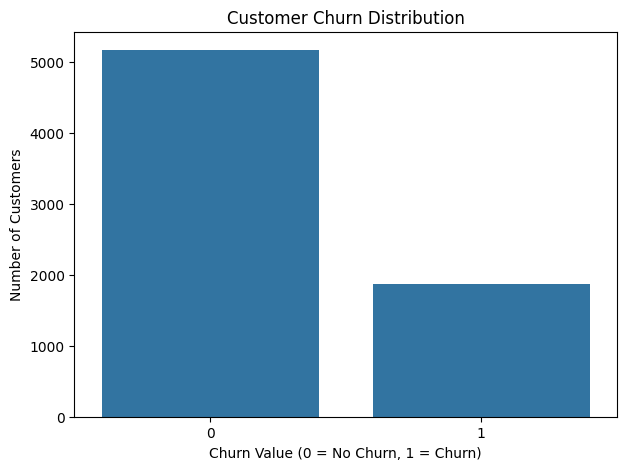

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn Value"
)

plt.title("Customer Churn Distribution")

plt.xlabel("Churn Value (0 = No Churn, 1 = Churn)")

plt.ylabel("Number of Customers")

plt.show()

In [31]:
# STEP 6: DATA CLEANING

df["Total Charges"] = (
    df["Total Charges"]
    .astype(str)
    .str.strip()
    .replace("", np.nan)
)

df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

print("Total Charges cleaned successfully!")

print(df["Total Charges"].dtype)

print("Missing Total Charges:",
      df["Total Charges"].isnull().sum())

Total Charges cleaned successfully!
float64
Missing Total Charges: 11


In [33]:
# FEATURE SELECTION

features = [

    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Tenure Months",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Monthly Charges",
    "Total Charges"

]

# Independent variables

X = df[features].copy()

# Dependent variable

y = df["Churn Value"].copy()

print("Feature Selection Completed!")

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

Feature Selection Completed!
Input Features Shape: (7043, 19)
Target Shape: (7043,)


In [35]:
# STEP 7: TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print("Training Dataset:", X_train.shape)

print("Testing Dataset:", X_test.shape)

Training Dataset: (5634, 19)
Testing Dataset: (1409, 19)


In [37]:
# STEP 8: IDENTIFY FEATURE TYPES

numeric_features = [

    "Tenure Months",
    "Monthly Charges",
    "Total Charges"

]

categorical_features = [

    col for col in features

    if col not in numeric_features

]

print("Numerical Features:")

print(numeric_features)

print("\nCategorical Features:")

print(categorical_features)

Numerical Features:
['Tenure Months', 'Monthly Charges', 'Total Charges']

Categorical Features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [39]:
numeric_transformer = Pipeline(

    steps=[

        ("imputer", SimpleImputer(
            strategy="median"
        )),

        ("scaler", StandardScaler())

    ]

)

In [41]:
categorical_transformer = Pipeline(

    steps=[

        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),

        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))

    ]

)

In [43]:
# COLUMN TRANSFORMER

preprocessor = ColumnTransformer(

    transformers=[

        ("num", numeric_transformer,
         numeric_features),

        ("cat", categorical_transformer,
         categorical_features)

    ],

    n_jobs=1

)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [45]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

print("Preprocessing completed successfully!")

print("Processed Training Shape:",
      X_train_processed.shape)

print("Processed Testing Shape:",
      X_test_processed.shape)

Preprocessing completed successfully!
Processed Training Shape: (5634, 46)
Processed Testing Shape: (1409, 46)


In [47]:
# STEP 9: INITIALIZE FIVE ML MODELS

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": SVC(
        probability=True,
        random_state=42
    )

}

print("Five models initialized successfully!")

for name in models:

    print(name)

Five models initialized successfully!
Logistic Regression
Decision Tree
KNN
Naive Bayes
SVM


In [49]:
# STEP 10: MODEL TRAINING

trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(
        X_train_processed,
        y_train
    )

    trained_models[name] = model

    print(name, "training completed!")

print("\nAll five models trained successfully!")


Training: Logistic Regression
Logistic Regression training completed!

Training: Decision Tree
Decision Tree training completed!

Training: KNN
KNN training completed!

Training: Naive Bayes
Naive Bayes training completed!

Training: SVM
SVM training completed!

All five models trained successfully!


In [50]:
# STEP 11: GENERATE PREDICTIONS

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(
        X_test_processed
    )

    predictions[name] = y_pred

    print("\nModel:", name)

    print("First 10 Predictions:")

    print(y_pred[:10])

print("\nPredictions generated successfully!")


Model: Logistic Regression
First 10 Predictions:
[0 1 0 0 0 1 0 0 0 0]

Model: Decision Tree
First 10 Predictions:
[0 0 0 1 0 0 1 1 0 1]

Model: KNN
First 10 Predictions:
[0 1 0 1 0 1 0 0 0 1]

Model: Naive Bayes
First 10 Predictions:
[0 1 0 1 0 1 1 0 0 1]

Model: SVM
First 10 Predictions:
[0 1 0 0 0 1 1 0 0 0]

Predictions generated successfully!


In [51]:
# STEP 12: MODEL EVALUATION

results = []

for name, model in trained_models.items():

    y_pred = predictions[name]

    y_prob = model.predict_proba(
        X_test_processed
    )[:, 1]

    accuracy = accuracy_score(
        y_test, y_pred
    )

    auc = roc_auc_score(
        y_test, y_prob
    )

    precision = precision_score(
        y_test, y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test, y_pred
    )

    results.append({

        "Model": name,

        "Accuracy": accuracy,

        "AUC": auc,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "MCC": mcc

    })


results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8020,0.8487,0.6435,0.5695,0.6043,0.4744
1,Decision Tree,0.7353,0.6715,0.5013,0.5294,0.5150,0.3333
2,KNN,0.7693,0.7965,0.5636,0.5802,0.5718,0.4141
3,Naive Bayes,0.7204,0.8150,0.4840,0.8075,0.6052,0.4413
4,SVM,0.7970,0.8126,0.6477,0.5160,0.5744,0.4483


In [52]:
# STEP 13: BEST MODEL IDENTIFICATION

best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("BEST PERFORMING MODEL")

print("Model:", best_model["Model"])

print("Accuracy:", best_model["Accuracy"])

print("AUC:", best_model["AUC"])

print("Precision:", best_model["Precision"])

print("Recall:", best_model["Recall"])

print("F1 Score:", best_model["F1 Score"])

print("MCC:", best_model["MCC"])

BEST PERFORMING MODEL
Model: Naive Bayes
Accuracy: 0.7203690560681334
AUC: 0.8149577617608308
Precision: 0.483974358974359
Recall: 0.8074866310160428
F1 Score: 0.6052104208416834
MCC: 0.44125456126364715


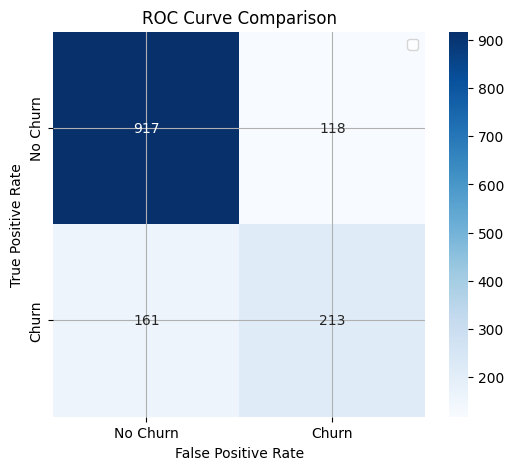

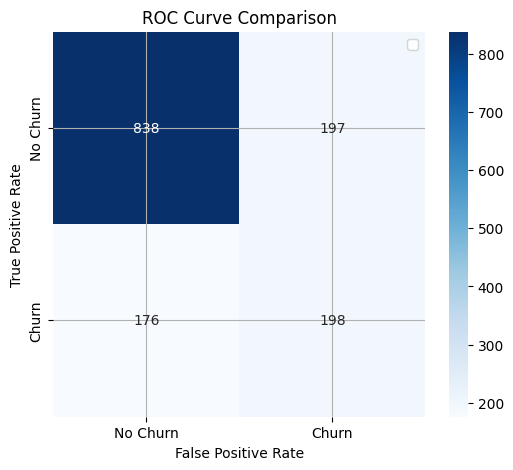

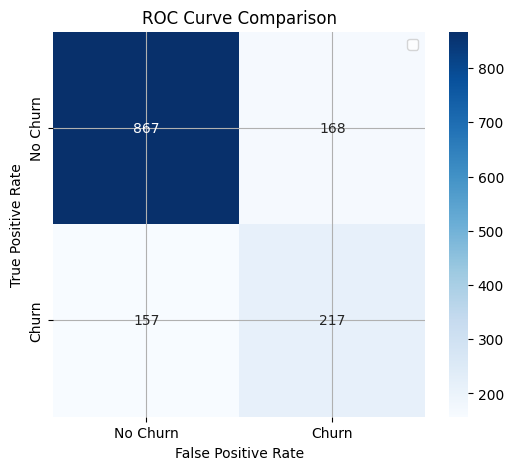

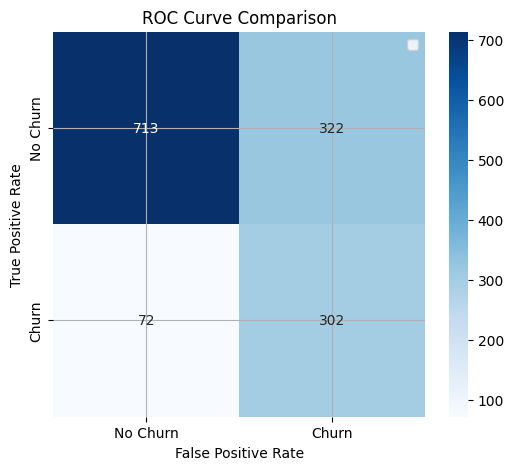

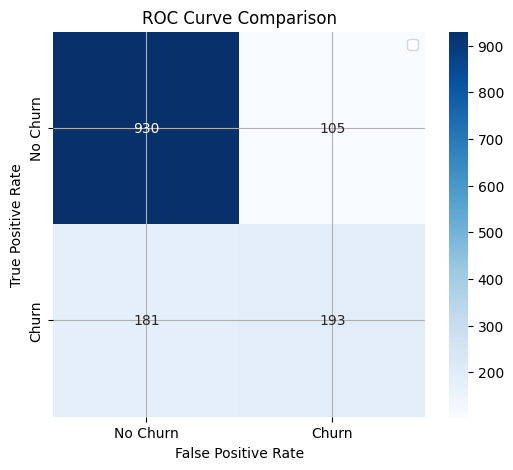

In [57]:
# STEP 14: CONFUSION MATRICES

for name, model in trained_models.items():

    y_pred = predictions[name]

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",

        xticklabels=["No Churn", "Churn"],

        yticklabels=["No Churn", "Churn"]
    )
    plt.xlabel("False Positive Rate")

    plt.ylabel("True Positive Rate")

    plt.title("ROC Curve Comparison")

    plt.legend()

    plt.grid()

    

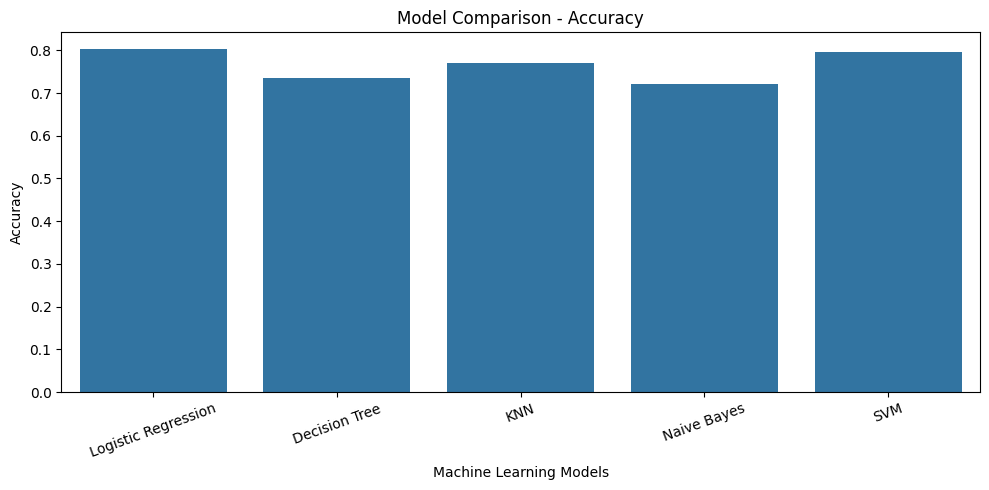

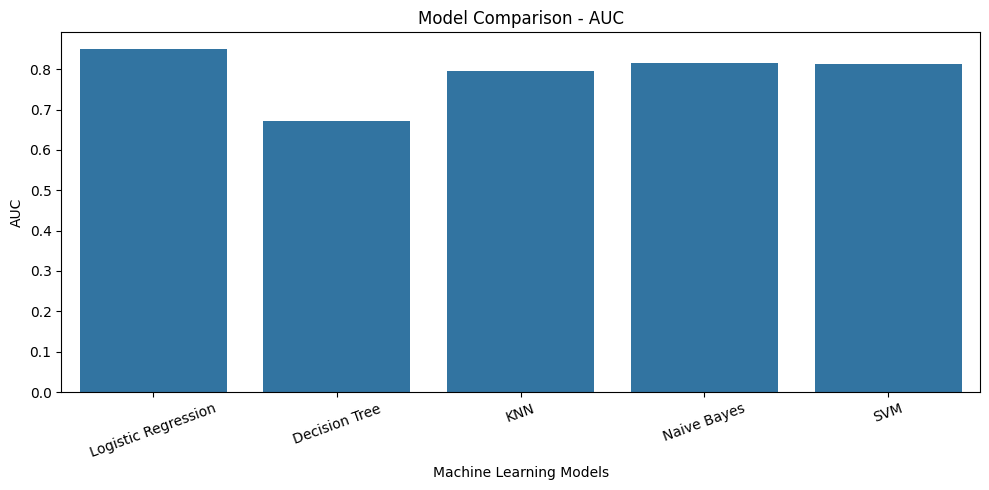

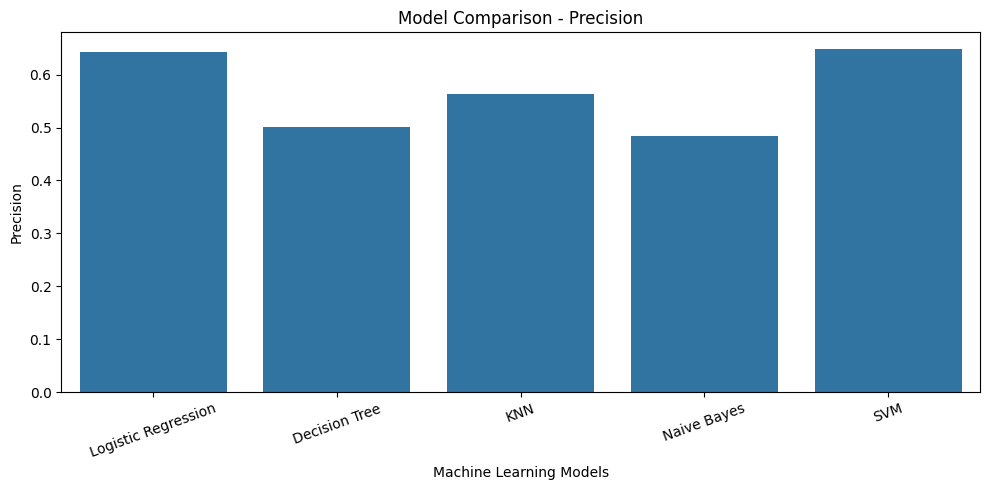

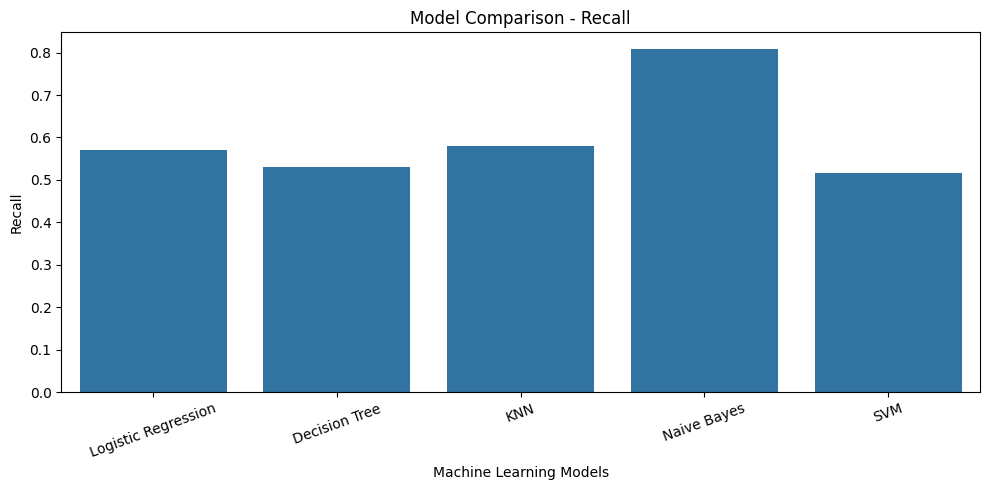

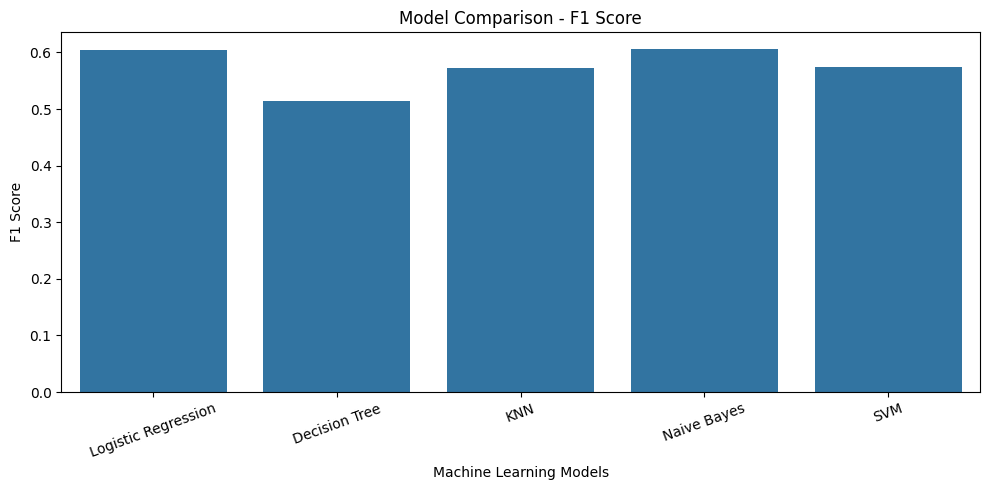

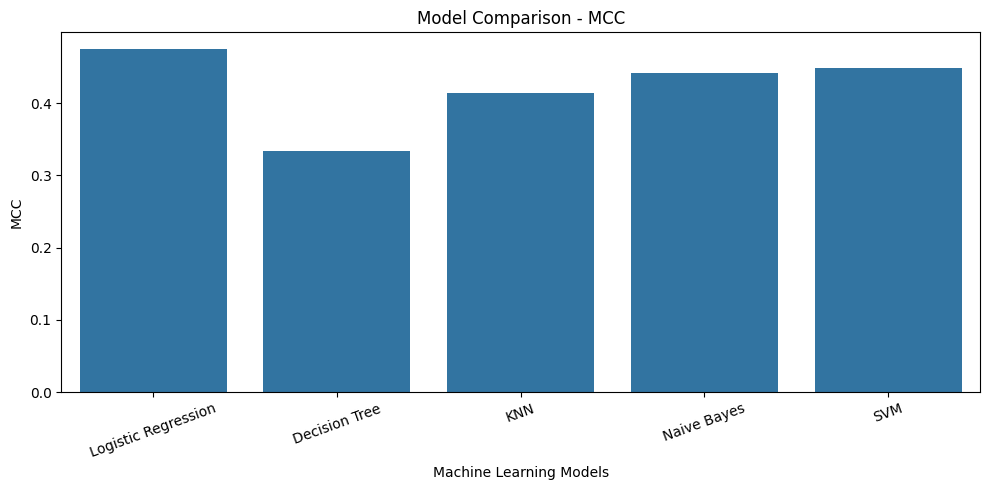

In [59]:
# STEP 16: MODEL PERFORMANCE GRAPHS

metrics = [

    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"

]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title("Model Comparison - " + metric)

    plt.xlabel("Machine Learning Models")

    plt.ylabel(metric)

    plt.xticks(rotation=20)

    plt.tight_layout()

    plt.show()

In [ ]:
# STEP 17: SAVE RESULTS

results_df.to_csv(
    "ML_Model_Comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

In [ ]:
# STEP 18: SAVE BEST MODEL

best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

best_classifier = trained_models[
    best_model_name
]

complete_model = Pipeline([

    ("preprocessor", preprocessor),

    ("classifier", best_classifier)

])

joblib.dump(
    complete_model,
    "Best_Customer_Churn_Model.pkl"
)

print("Best Model:", best_model_name)

print("Best model saved successfully!")

In [61]:
# STEP 19: CLASSIFICATION REPORTS

for name, model in trained_models.items():

    print("\n================================")

    print("CLASSIFICATION REPORT:", name)

    print("================================")

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

    No Churn       0.83      0.81      0.82      1035
       Churn       0.50      0.53      0.51       374

    accuracy                           0.74      1409
   macro avg       0.66      0.67      0.67      1409
weighted avg       0.74      0.74      0.74      1409


CLASSIFICATION REPORT: KNN
              precision    recall  f1-score   support

    No Churn       0.85      0.84      0.84      1035
       Churn       0.56      0.58      0.57       374

    accuracy                           0.77      1409
   macro avg      

In [63]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [65]:
import streamlit as st

print("Streamlit Version:", st.__version__)

print("Streamlit installed successfully!")

Streamlit Version: 1.66.1
Streamlit installed successfully!


In [67]:
import os

print("Project Files:")

for file in os.listdir():
    print(file)

Project Files:
app.py
requirements.txt
.ipynb_checkpoints
anaconda_projects
Telco_customer_churn.csv
ML_Model_Comparison.csv
Best_Customer_Churn_Model.pkl
Assignment2_MachineLearning.ipynb


In [69]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load("Best_Customer_Churn_Model.pkl")

# Application title
st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("Customer Churn Prediction System")

st.write(
    "Predict whether a telecom customer is likely to leave the service."
)

st.sidebar.header("Customer Information")

# Customer inputs

gender = st.sidebar.selectbox(
    "Gender", ["Male", "Female"]
)

senior = st.sidebar.selectbox(
    "Senior Citizen", ["Yes", "No"]
)

partner = st.sidebar.selectbox(
    "Partner", ["Yes", "No"]
)

dependents = st.sidebar.selectbox(
    "Dependents", ["Yes", "No"]
)

tenure = st.sidebar.number_input(
    "Tenure Months", 0, 100, 12
)

phone = st.sidebar.selectbox(
    "Phone Service", ["Yes", "No"]
)

multiple = st.sidebar.selectbox(
    "Multiple Lines", ["Yes", "No", "No phone service"]
)

internet = st.sidebar.selectbox(
    "Internet Service",
    ["DSL", "Fiber optic", "No"]
)

security = st.sidebar.selectbox(
    "Online Security",
    ["Yes", "No", "No internet service"]
)

backup = st.sidebar.selectbox(
    "Online Backup",
    ["Yes", "No", "No internet service"]
)

device = st.sidebar.selectbox(
    "Device Protection",
    ["Yes", "No", "No internet service"]
)

tech = st.sidebar.selectbox(
    "Tech Support",
    ["Yes", "No", "No internet service"]
)

tv = st.sidebar.selectbox(
    "Streaming TV",
    ["Yes", "No", "No internet service"]
)

movies = st.sidebar.selectbox(
    "Streaming Movies",
    ["Yes", "No", "No internet service"]
)

contract = st.sidebar.selectbox(
    "Contract",
    ["Month-to-month", "One year", "Two year"]
)

paperless = st.sidebar.selectbox(
    "Paperless Billing", ["Yes", "No"]
)

payment = st.sidebar.selectbox(
    "Payment Method",
    [
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ]
)

monthly = st.sidebar.number_input(
    "Monthly Charges", 0.0, 200.0, 70.0
)

total = st.sidebar.number_input(
    "Total Charges", 0.0, 10000.0, 840.0
)

# Prepare input data

input_data = pd.DataFrame([{

    "Gender": gender,
    "Senior Citizen": senior,
    "Partner": partner,
    "Dependents": dependents,
    "Tenure Months": tenure,
    "Phone Service": phone,
    "Multiple Lines": multiple,
    "Internet Service": internet,
    "Online Security": security,
    "Online Backup": backup,
    "Device Protection": device,
    "Tech Support": tech,
    "Streaming TV": tv,
    "Streaming Movies": movies,
    "Contract": contract,
    "Paperless Billing": paperless,
    "Payment Method": payment,
    "Monthly Charges": monthly,
    "Total Charges": total

}])

# Customer Churn Prediction

st.subheader("Customer Churn Prediction")

if st.button("Predict Customer Churn"):

    try:

        prediction = model.predict(input_data)[0]

        probability = model.predict_proba(input_data)[0][1]

        st.subheader("Prediction Results")

        col1, col2 = st.columns(2)

        with col1:

            if prediction == 1:
                st.error("Customer is likely to CHURN")
            else:
                st.success("Customer is likely to STAY")

        with col2:

            st.metric(
                "Churn Probability",
                f"{probability * 100:.2f}%"
            )

        st.progress(float(probability))

        st.subheader("Customer Input Details")

        st.dataframe(input_data)

    except Exception as e:

        st.error("Prediction failed!")

        st.exception(e)

Overwriting app.py


In [71]:
import os

print(os.listdir())

['app.py', 'requirements.txt', '.ipynb_checkpoints', 'anaconda_projects', 'Telco_customer_churn.csv', 'ML_Model_Comparison.csv', 'Best_Customer_Churn_Model.pkl', 'Assignment2_MachineLearning.ipynb']


In [73]:
import os

print("Current Directory:", os.getcwd())

print("App.py exists:", os.path.exists("app.py"))

print("Model exists:",
      os.path.exists("Best_Customer_Churn_Model.pkl"))

Current Directory: /home/s2026aj05112/workspace/ML Assignment2
App.py exists: True
Model exists: True


In [94]:
readme_content = """
# Customer Churn Prediction System

## Project Overview
This project uses Machine Learning to predict whether a
telecommunication customer is likely to leave the service.

## Dataset
Telco Customer Churn Dataset.

## Machine Learning Models
The following models were developed and compared:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Naive Bayes
5. Support Vector Machine (SVM)

## Best Performing Model
Naive Bayes was selected based on the model comparison
results, with an accuracy of approximately 72.04%.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Streamlit

## Application Features
- Customer information input
- Customer churn prediction
- Churn probability display

## Project Files
- app.py
- Best_Customer_Churn_Model.pkl
- ML_Model_Comparison.csv
- requirements.txt
- Assignment2_MachineLearning.ipynb

## How to Run the Application

Install dependencies:

pip install -r requirements.txt

Run Streamlit:

streamlit run app.py

## Conclusion
The project demonstrates how Machine Learning can help
telecommunication companies identify customers who may churn.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [96]:
import os

print("README.md exists:", os.path.exists("README.md"))
print("Current directory:", os.getcwd())

README.md exists: True
Current directory: /home/s2026aj05112/workspace/ML Assignment2


In [98]:
!streamlit run app.py --server.headless true



2026-11-02 23:33:03.639 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://10.3.23.129:8502
  External URL: http://13.235.197.17:8502

^C
  Stopping...


In [77]:
import joblib

model = joblib.load("Best_Customer_Churn_Model.pkl")

print("Model Type:", type(model))

print("Model Classes:", model.classes_)

Model Type: <class 'sklearn.pipeline.Pipeline'>
Model Classes: [0 1]


In [80]:
import pandas as pd

input_data = pd.DataFrame([{
    'Gender': 'Male',
    'Senior Citizen': 'No',
    'Partner': 'Yes',
    'Dependents': 'No',
    'Tenure Months': 12,
    'Phone Service': 'Yes',
    'Multiple Lines': 'No',
    'Internet Service': 'Fiber optic',
    'Online Security': 'No',
    'Online Backup': 'No',
    'Device Protection': 'No',
    'Tech Support': 'No',
    'Streaming TV': 'No',
    'Streaming Movies': 'No',
    'Contract': 'Month-to-month',
    'Paperless Billing': 'Yes',
    'Payment Method': 'Electronic check',
    'Monthly Charges': 85.50,
    'Total Charges': 1026.00
}])

print("Customer input created successfully!")

display(input_data)

Customer input created successfully!


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,Male,No,Yes,No,12,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,85.5,1026.0


In [82]:
prediction = model.predict(input_data)

probability = model.predict_proba(input_data)

print("Prediction:", prediction[0])

print("Prediction Probabilities:", probability)

if prediction[0] == 1:
    print("Customer is likely to CHURN")
else:
    print("Customer is NOT likely to CHURN")

print("Churn Probability:",
      round(probability[0][1] * 100, 2), "%")

Prediction: 1
Prediction Probabilities: [[2.52738173e-08 9.99999975e-01]]
Customer is likely to CHURN
Churn Probability: 100.0 %


In [102]:
import os

print("PROJECT FILES")

for file in os.listdir():
    print(file)

PROJECT FILES
app.py
requirements.txt
.ipynb_checkpoints
Telco_customer_churn.csv
ML_Model_Comparison.csv
README.md
Best_Customer_Churn_Model.pkl
Assignment2_MachineLearning.ipynb
